In [1]:
## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

os.environ.get("ROOTSYS")

"""
run with:
see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab
"""

'\nrun with:\nsee code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab\n'

In [2]:
# 1. have to also handle uncertainties on bins (from ROOT bkg subtraction) 
#   and how do i handle this throughout (for ks test, etc)

# 2. is my zero PE bin in data okay?

# 3. to keep the rate thing consistent, I think I need one global variable 
#   to scale all of the simulation data.

# 4. ks test is sensitive to the far range. Do I do log-bin spacing?

# to do rn:
# 1. 

# ? is commong scaling to different heights correct?

# change anaStructs object so that i don't have to distinguish between 
# raw or rate data. just make two histograms for each object

## Framework items ##
# 1. somehow group all 'heights' and do scaling minimization

# 2. group the correct mac runs together (heights vs light yields)

# 3. do global minimization

# 4. sum reduced chi2 as 'weighted sum'

# change FullMCRun.setup_forComparison to setup for plotting, then have something else to 
# the range of the bins used for KS test

# fix bkg subtraction. do bkg_rate * runTime of data

# I need to combine both classes/helpers (on gitlab it will become an issue)

# some bins are negative after bkg subtraction --> make them zero

# do i add the chi2 from each histogram

# markov chain and run the MC 'live'


In [ ]:
## Overvoltage at 48 V is 4.5V (from noise_extraction.ipynb)
pCA = 0.35 # first VUV4 paper, 163K

# from second Giacomo nEXO paper. Our SiPM is VUV4-Q-50
pCA = 0.17

In [3]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(300)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [4]:
## loading tools for data
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

sys.path.append(os.environ.get("CF4G4"))
from Batch.helpers.FileGetters import *
from Batch.helpers.G4_runClasses import *
from Batch.helpers.G4_macHelpers import *

print(sys.path)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/helpers']


In [5]:
## ------------- User Inputs ------------- ##
## USER INPUTS (kinda bad ngl) ##
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO2D = False

#QVAR_USE = "qRCFlat"
# QVAR_USE = "qRCFixed"
QVAR_USE = "qFlat"
# QVAR_USE = "qFixed"
PECUTVALUE = 0.5

## Paths to files, runLists
defPath = str(os.environ["CF4HOME"])+"/procData/" # where to get everything
bkgRunPath = "runLists/analysis1/bkgLists/"       # bkg run list files

## -------- physics and bkg runs -------- ##
runID_cs_bare_heights = [202203101341, 202203101306, 202203101150, 202203101534, 202203101506]
cs_bare_heights = [26.5, 28,	30.5,	32,	34.5]

runID_cs_LP_heights = [202204111600,	202204111454,	202204111423, 202204121321]
cs_LP_heights = [26, 28.5,	30.5, 32]

physicsList = runID_cs_bare_heights + runID_cs_LP_heights

# bkg runs
bkgList_0310 = np.loadtxt(defPath + bkgRunPath+ "date_0310-48V.txt", dtype=int).tolist()
bkgList_0411 = np.loadtxt(defPath + bkgRunPath+ "date_0411-48V.txt", dtype=int).tolist()

# final inputs into code
allBkgs = bkgList_0310 + bkgList_0411
allRuns = allBkgs + physicsList

In [22]:
## Get all data RC objects, build needed SPE histograms ##
ROOT.gErrorIgnoreLevel = ROOT.kError
rcList = [] ## everything from here
fList = []

speList = []
chi2list = []

# loading data and SPE analysis
# everything is in rcList
for run in allRuns:
  f = ROOT.TFile(defPath + "analysis1/npv1_" + str(run) + ".root", "READ") #file opens
  fList.append(f) # NEED THIS to keep ttrees persistent (all reference in Python)

  tt = f.Get("tt")
  rcObj = RunClass(run, tt)

  rcObj.assign_height(runID_cs_bare_heights, cs_bare_heights)
  rcObj.assign_height(runID_cs_LP_heights, cs_LP_heights)

  rcObj.computeSPE(width = 15, verbose=VERBOSE, varname=QVAR_USE, channels = [i for i in range(NCHAN)])
  rcList.append(rcObj)

  for chan in rcObj.mChannels:
    # print(chan.mSpe.chi2)
    speList.append(chan.mSpe.spe)
    chi2list.append(chan.mSpe.chi2)
ROOT.gErrorIgnoreLevel = ROOT.kUnset
print("Done Calculating SPE")

Done Calculating SPE


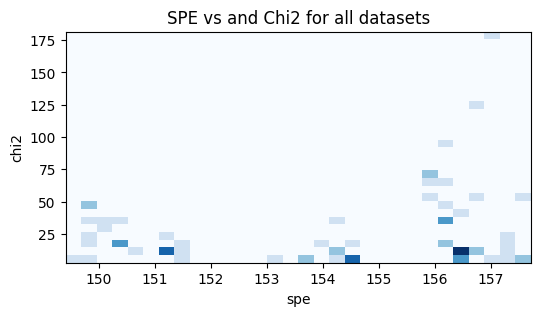

In [25]:
## checking spe and chi2 values
plt.figure(figsize=(6, 3))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.title("SPE vs and Chi2 for all datasets")
plt.xlabel("spe")
plt.ylabel("chi2")
plt.show()

In [8]:
#### Sorting RC objects ####
rcl_Bkg_0310 = SORTING.pickListOfRC(bkgList_0310, rcList) # get all RC background objects
rcl_cs_bare_heights = SORTING.pickListOfRC(runID_cs_bare_heights, rcList)

rcl_Bkg_0411 = SORTING.pickListOfRC(bkgList_0411, rcList) # get all RC background objects
rcl_cs_lp_heights = SORTING.pickListOfRC(runID_cs_LP_heights, rcList)

######## Building Full Spectra ########
binLow = 0.5
binHigh = 100.5
Nbins = 100.
binWidth = (binHigh - binLow) / Nbins
hReference = TH1F("hReference", "hReference", int(Nbins), binLow, binHigh) # histogram that everything is built off
hReference.Sumw2(True)

# building all SPE spectra
for rc in rcList:
  rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate = True)

# building averaged bkg spectra
hNPE_bkg_0310 = hReference.Clone("hNPE_bkg_0310") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0310, QVAR_USE, hNPE_bkg_0310, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

hNPE_bkg_0411 = hReference.Clone("hNPE_bkg_0411") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0411, QVAR_USE, hNPE_bkg_0411, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

done filling histogram: hNPE_202203101136
done filling histogram: hNPE_202203101245
done filling histogram: hNPE_202203101333
done filling histogram: hNPE_202203101424
done filling histogram: hNPE_202203101457
done filling histogram: hNPE_202203101526
done filling histogram: hNPE_202203101553
done filling histogram: hNPE_202204111213
done filling histogram: hNPE_202204111229
done filling histogram: hNPE_202204111247
done filling histogram: hNPE_202204111323
done filling histogram: hNPE_202204111434
done filling histogram: hNPE_202204111520
done filling histogram: hNPE_202204111623
done filling histogram: hNPE_202203101341
done filling histogram: hNPE_202203101306
done filling histogram: hNPE_202203101150
done filling histogram: hNPE_202203101534
done filling histogram: hNPE_202203101506
done filling histogram: hNPE_202204111600
done filling histogram: hNPE_202204111454
done filling histogram: hNPE_202204111423
done filling histogram: hNPE_202204121321
done building fast bkg histogram f

In [9]:
## plotting reference (bkg) figures 
c0 = TCanvas()
c0.SetLogy()

hReference.GetXaxis().SetRangeUser(0, 20)
hReference.Draw("hist")
hReference.SetTitle("0311 bkg data")

for rc in rcl_Bkg_0310:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0310.index(rc)+1)
  h.SetLineWidth(3)

  h.Draw("hist same E")
c0.Update()
c0.Draw()

c1 = TCanvas()
c1.SetLogy()

hReference2 = hReference.Clone("hReference2")
hReference2.Draw("hist")
hReference2.SetTitle("0411 bkg data")
hReference2.GetYaxis().SetRangeUser(0.001, 100)

for rc in rcl_Bkg_0411:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0411.index(rc)+1)
  h.SetLineWidth(2)

  h.Draw("hist same E")

c1.Update()
c1.Draw()

In [10]:
## Get and build the bkg corrected spectra
print("Bare:")
for rc in rcl_cs_bare_heights:
  rc.FindClosestRC(rcl_Bkg_0310)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)

print("\n Filtered")
for rc in rcl_cs_lp_heights:
  rc.FindClosestRC(rcl_Bkg_0411)
  rc.BuildCorrSpectrum()
  rc.setup_forComparison()
  print(rc.mHeight)


Bare:
26.5
28
30.5
32
34.5

 Filtered
26
28.5
30.5
32


In [11]:
## looking for specific RC objects (data runs)
FindRCbyHeight = lambda h, rclist: next((rc for rc in rclist if rc.GetHeight() == h), None)

rcBare_0cm = FindRCbyHeight(32, rcl_cs_bare_heights)
rcBare_1d5cm = FindRCbyHeight(30.5, rcl_cs_bare_heights)
rcBare_4cm = FindRCbyHeight(28., rcl_cs_bare_heights)
rcBare_55cm = FindRCbyHeight(26.5, rcl_cs_bare_heights)
rcBare_55cm.print()



runID: 202203101341
Nevents: 60443.00,   time: 33.82 min
average Rate: 29.79 Hz
height = 26.50
chID:0: spe = 151.43 +/- 0.23     maxChi2 = 15.29
chID:1: spe = 154.37 +/- 0.24     maxChi2 = 35.25
chID:2: spe = 156.33 +/- 0.27     maxChi2 = 46.82


In [12]:
# rcBare_4cm.tt.Show(0)
  

In [13]:
## loading in MC data
pathToFiles = os.environ.get("CF4G4")+"/Batch/may5_2023-manualTesting_gammaHeights/"

# dat = get_all_root_files(pathToFiles)
files = get_all_root_files(pathToFiles)
for f in files:
  print(f)
# print(files)

fname = "Cs137_1d5cm"
mc_1d5cm = FullMCRun(macName = pathToFiles+fname)
mc_1d5cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

fname2 = "Cs137_4cm"
mc_4cm = FullMCRun(macName = pathToFiles+fname2)
mc_4cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

fname3 = "Cs137_0cm"
mc_0cm = FullMCRun(macName = pathToFiles+fname3)
mc_0cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

# runList = [[rcBare_0cm, mc_0cm], [rcBare_1d5cm, mc_1d5cm], [rcBare_4cm, mc_4cm]]

fname4 = "Cs137_5d5"
mc_55cm = FullMCRun(macName = pathToFiles+fname4)
mc_55cm.setup_forComparison(Nbins, lowRange=binLow, maxRange=binHigh)

hScale = 32. # H measured - this = height above SiPM (MC)
heightMapping = lambda h: hScale - h
print(heightMapping(28))
print(heightMapping(5.5))

mcList = [mc_0cm, mc_1d5cm, mc_4cm, mc_55cm]
dataList = [rcBare_0cm, rcBare_1d5cm, rcBare_4cm, rcBare_55cm]
endRange_ksTest = [60, 25, 12, 8]


# macList = 

Cs137_4cm_big.root
Cs137_-0d5cm.root
Cs137_4cm.root
Cs137_5d5.root
Cs137_0cm.root
Cs137_1d5cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_1d5cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_4cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_0cm.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch/may5_2023-manualTesting_gammaHeights/Cs137_5d5.root
4.0
26.5


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'file', 'mBinX', 'mBin_Edges', 'mDetPars', 'mNPE', 'mPhysPars', 'mRaw_Counts', 'mRunPars', 'mTtree', 'normAndscale', 'setup_forComparison']


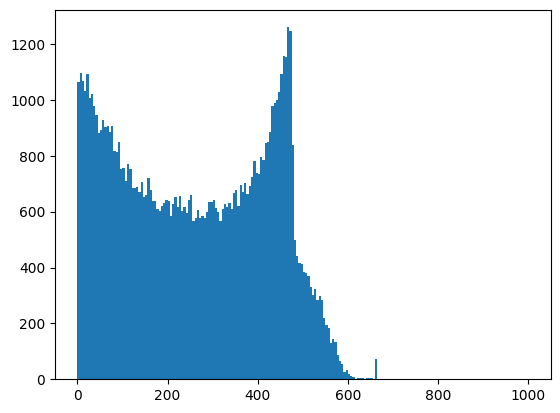

In [14]:
print(dir(mc_1d5cm))

mc_4cm.mTtree.keys()
plt.hist(mc_4cm.mTtree['fEdepInCyl_kev'].array(), bins = 200, range = (0, 1000))
# plt.hist(mc_1d5cm.mNPE, bins = int(Nbins), range=(0, binHigh))

plt.show()



In [164]:
# ## my test class to minimize per run ##

# class MCrun_fixedPars(object):
  
#   def __init__(self, physRuns, mcRuns): # pass a list of data and MC runs (RC objects and FullMCRun)

## scaling ##
binStart = 0
binEnd = 1

# scaling analytically with 1.5cm
dataArea = sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd])

# mcCounts, mcEdges = np.histogram(mc_1d5cm.mNPE, bins = int(Nbins), range=(0, binHigh))
mcScale = dataArea/np.sum(mc_0cm.mRaw_Counts[binStart:binEnd]) # now it is 1
# mcScale *= 100.
  
print(np.sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd]))
print(mcScale * np.sum(mc_0cm.mRaw_Counts[binStart:binEnd]))


1675.0780630867487
1675.0780630867487


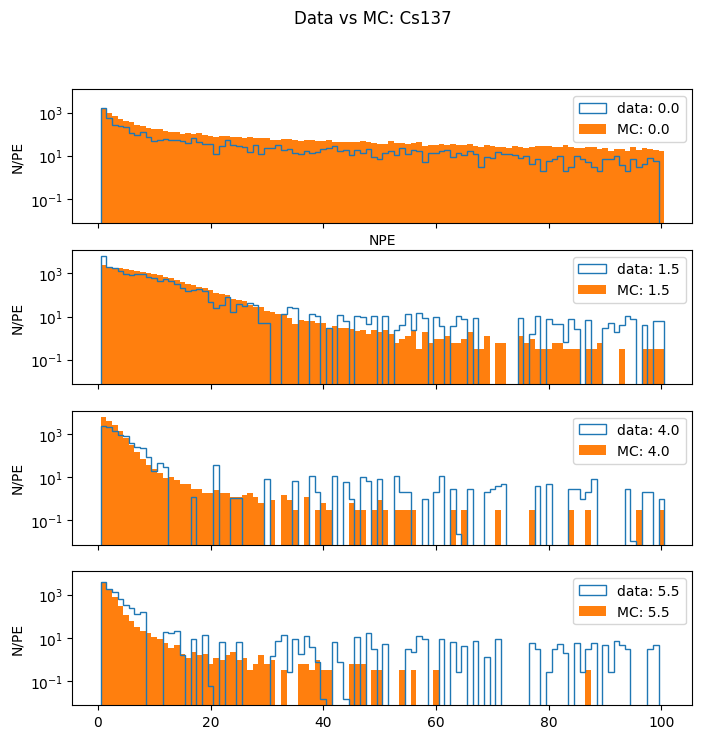

: 

In [185]:
fig, axs = plt.subplots(4, 1, figsize = (8, 8), sharey=True, sharex=True)
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]
ax4 = axs[3]

mcScale = 0.3119 # from a fit, adding total chi2

# 32 = 0 cm run
# areaData = sum(rcBare_0cm.mBin_rawCounts[binStart:binEnd])
ax1.hist(x = rcBare_0cm.mBinX, bins = rcBare_0cm.mBin_edges, weights = rcBare_0cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_0cm.mHeight))
ax1.hist(x = mc_0cm.mBinX, bins = mc_0cm.mBin_Edges, weights=mc_0cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_0cm.mRunPars.gammaHeight))

# 30.5 = 1.5 cm run
ax2.hist(x = rcBare_1d5cm.mBinX, bins = rcBare_1d5cm.mBin_edges, weights = rcBare_1d5cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_1d5cm.mHeight))
ax2.hist(x = mc_1d5cm.mBinX, bins = mc_1d5cm.mBin_Edges, weights=mc_1d5cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_1d5cm.mRunPars.gammaHeight))

# 34  =  4cm 
ax3.hist(x = rcBare_4cm.mBinX, bins = rcBare_4cm.mBin_edges, weights = rcBare_4cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale -rcBare_4cm.mHeight))
ax3.hist(x = mc_4cm.mBinX, bins = mc_4cm.mBin_Edges, weights=mc_4cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_4cm.mRunPars.gammaHeight))

# 26.5 = 5.5cm
ax4.hist(x = rcBare_55cm.mBinX, bins = rcBare_55cm.mBin_edges, weights = rcBare_55cm.mBin_rawCounts, histtype="step", label = "data: " + str(hScale - rcBare_55cm.mHeight))
ax4.hist(x = mc_55cm.mBinX, bins = mc_55cm.mBin_Edges, weights=mc_55cm.mRaw_Counts * mcScale, label = "MC: " + str(mc_55cm.mRunPars.gammaHeight))
# plt.hist(x = mcEdges[:-1], bins = mcEdges, weights=mcCounts, label = "MC")

for ax in axs.flat:
  ax.set_ylabel("N/PE")
  ax.legend()

ax1.set_xlabel("NPE")
fig.suptitle("Data vs MC: Cs137")
ax1.set_yscale("log")
# ax1.set_ylim(0, 20)
# ax1.set_xlim(0, 30)

# plt.legend()
plt.show()
# print(rcBare_0cm.mBin_edges[0])

# mcEdges[0:4]

In [166]:
from scipy.stats import ks_2samp
from scipy.stats import anderson_ksamp
from scipy.stats import chisquare
from scipy.stats import cramervonmises_2samp

from scipy.stats import chi2

import scipy.optimize as spOpt

import copy

In [179]:
def totalChi2(scaleFactor, mcList, dataList, myInfo=[None, None], firstBin = 0, countLimit = 10.):
  chi2 = 0.
  totalNDOF = 0

  for mc, data in zip(mcList, dataList):
    # print(scaleFactor * mc.mRaw_Counts[0:20])
    lastBin = np.where(data.mBin_rawCounts < countLimit)[0][0]
    if data.mBin_rawCounts[lastBin] <= 0:
      lastBin -= 1
    while mc.mRaw_Counts[lastBin] <= countLimit:
      lastBin -= 1
    # print(lastBin, data.mBin_rawCounts[lastBin], scaleFactor * mc.mRaw_Counts[lastBin])

    mcBins = scaleFactor * mc.mRaw_Counts[firstBin:lastBin]
    dataBins = data.mBin_rawCounts[firstBin:lastBin]
    chi2Run = np.sum((dataBins - mcBins)**2/mcBins)

    totalNDOF += lastBin - firstBin
    chi2 += chi2Run

  myInfo[0] = scaleFactor
  myInfo[1] = chi2
  myInfo[2] = totalNDOF - 1
  # print(scaleFactor, "\n")
  return chi2/(totalNDOF - 1)

def totalReducedChi2(scaleFactor, mcList, dataList, myInfo=[None, None], firstBin = 0, countLimit = 10.):
  reducedChi2 = 0.

  for mc, data in zip(mcList, dataList):
    # print(scaleFactor * mc.mRaw_Counts[0:20])
    lastBin = np.where(data.mBin_rawCounts < countLimit)[0][0]
    if data.mBin_rawCounts[lastBin] <= 0:
      lastBin -= 1
    while mc.mRaw_Counts[lastBin] <= countLimit:
      lastBin -= 1
    # print(lastBin, data.mBin_rawCounts[lastBin], scaleFactor * mc.mRaw_Counts[lastBin])

    mcBins = scaleFactor * mc.mRaw_Counts[firstBin:lastBin]
    dataBins = data.mBin_rawCounts[firstBin:lastBin]
    chi2Run = np.sum((dataBins - mcBins)**2/mcBins)

    NDOF = lastBin - firstBin
    reducedChi2 += chi2Run/NDOF

  myInfo[0] = scaleFactor
  myInfo[1] = reducedChi2
  myInfo[2] = -1
  # print(scaleFactor, "\n")
  return reducedChi2

In [180]:


info = [None, None, None]
infoReduced = copy.copy(info)

totalChi2(mcScale, mcList, dataList, info)

totalReducedChi2(mcScale, mcList, dataList, infoReduced)

print(info)
print(infoReduced)

[0.33019476899009437, 17600.6373953134, 93]
[0.33019476899009437, 1065.1493586254503, -1]


In [183]:
fit = spOpt.minimize(totalChi2, x0 = [2*mcScale], args = (mcList, dataList, info), bounds = [[1e-4, 100.*mcScale]])
fitReduced = spOpt.minimize(totalReducedChi2, x0 = [2*mcScale], args = (mcList, dataList, infoReduced), bounds = [[1e-4, 100.*mcScale]])
print(mcScale)
print(fit)
print(info, "\n ------------------------------------- \n")
print(fitReduced)
print(infoReduced)

0.33019476899009437
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 185.24987841880053
        x: [ 3.029e-01]
      nit: 6
      jac: [ 1.336e-04]
     nfev: 22
     njev: 11
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>
[array([0.30293686]), 17228.238692948573, 93] 
 ------------------------------------- 

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 1054.2981998141986
        x: [ 3.119e-01]
      nit: 5
      jac: [-2.274e-05]
     nfev: 16
     njev: 8
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>
[array([0.31193548]), 1054.2981998141984, -1]


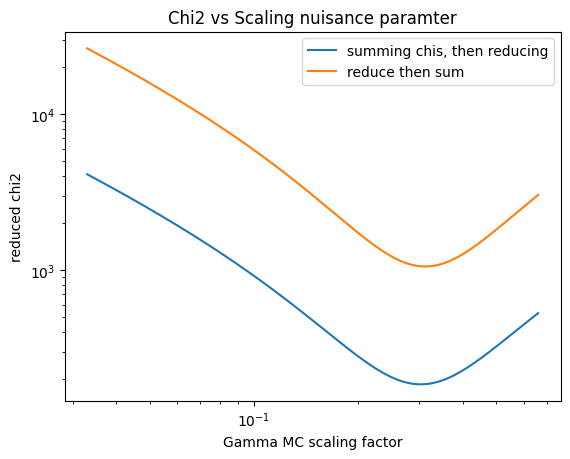

In [182]:
## testing manually
totalChi2(mcScale, mcList, dataList, info)
x_scaleValues = np.linspace(mcScale/10., 2*mcScale, 1000)
y_chiValues = []
y_chiReduced = []

for scale in x_scaleValues:
  chi = totalChi2(scale, mcList, dataList, info)
  y_chiValues.append(chi)

  reducedChi = totalReducedChi2(scale, mcList, dataList, infoReduced)
  y_chiReduced.append(reducedChi)

plt.plot(x_scaleValues, y_chiValues, label = "summing chis, then reducing")
plt.plot(x_scaleValues, y_chiReduced, label = "reduce then sum")
plt.yscale("log")
plt.xscale("log")

plt.xlabel("Gamma MC scaling factor")
plt.ylabel("reduced chi2")
plt.title("Chi2 vs Scaling nuisance paramter")

plt.legend()

plt.show()

In [51]:
# ## define function to be minimized

# def FixedPars_Likelihood(scaling, mcList, dataList):
LLksp = 0.
LLcv = 0.
firstBin = binStart
  
for i, (mc, data) in enumerate(zip(mcList, dataList)):
  endRange = endRange_ksTest[i]
  dArr = data.mBin_rawCounts[firstBin:endRange]
  mcArr = mcScale * mc.mRaw_Counts [firstBin:endRange]

  ks_statistic, ksp_value = ks_2samp(dArr, mcArr)
  # an_statistic, crit, ap_value = anderson_ksamp([dArr, mcArr], midrank = True)
  cram = cramervonmises_2samp(dArr, mcArr)

  myChi2 = (dArr - mcArr)**2/mcArr

  # print(i, mc, data)
  print(f"height:{mc.mRunPars.gammaHeight}   KS statistic: {ks_statistic:0.4f}, P-value: {ksp_value}")
  # print(f"   An statistic: {an_statistic:0.2E}, P-value: {ap_value}")
  print(f"   cram statistic: {cram.statistic:0.2E}, P-value: {cram.pvalue} \n")
  LLksp += ksp_value
  LLcv += cram.pvalue


print(f"KS Liklihood = {LLksp}")
print(f"CV Liklihood = {LLcv}")

height:0.0   KS statistic: 0.5833, P-value: 8.642404684557224e-10
   cram statistic: 3.35E+00, P-value: 1.1740159067130662e-08 

height:1.5   KS statistic: 0.2000, P-value: 0.7102038997076623
   cram statistic: 1.03E-01, P-value: 0.5910034965574833 

height:4.0   KS statistic: 0.1667, P-value: 0.9984852944874484
   cram statistic: 6.94E-02, P-value: 0.8191346948918627 

height:5.5   KS statistic: 0.5000, P-value: 0.2826728826728826
   cram statistic: 2.03E-01, P-value: 0.3135975135975136 

KS Liklihood = 1.9913620777322336
CV Liklihood = 1.7237357167870186


In [ ]:
## doing first KS test ##


ks_statistic, p_value = ks_2samp(rcBare_1d5cm.mBin_contents[binStart:binEnd], mcCounts[binStart:binEnd])

print(f"KS statistic: {ks_statistic}")
print(f"P-value: {p_value}")


KS statistic: 0.6956521739130435
P-value: 1.3001792757076406e-05


In [ ]:
len(rcBare_1d5cm.mBin_contents)
len(mcCounts)

80